# Explainable Fake News Headline Analyzer — End-to-End Google Colab Notebook

**Course:** AL-2002 Artificial Intelligence Laboratory (Fall 2026, Section BCY-5A)  
**University:** FAST — National University of Computer and Emerging Sciences (Karachi Campus)  
**Instructor:** Miss Amma Aslam  
**Project Idea:** Idea No. 19 (Part B — Applied and Data Projects)  
**Repository:** [HasnainMemon04/fake-news-headline-analyzer](https://github.com/HasnainMemon04/fake-news-headline-analyzer)

### Team Members & Module Ownership
| Position | Name | Roll Number | Primary Modules & Responsibilities |
| :--- | :--- | :--- | :--- |
| **Group Leader** | Muhammad Hasnain Memon | `24K-2001` | Architecture, `src/agents.py`, `src/experiments.py`, evaluation & repository coordination |
| **Member 2** | Akbar Hussain | `24K-2026` | Data acquisition (`src/dataset.py`), EDA (`src/analysis.py`), K-Means (`src/topics.py`) & visualizations |
| **Member 3** | Ateeb Ahmed Qureshi | `24K-2036` | Streamlit interface (`src/app.py`), explainability (`src/explanations.py`), testing & documentation |

---
### Overview & Narrative Structure
Upload this notebook to **Google Colab** and select **Runtime → Run all**. A CPU runtime is sufficient. For local Jupyter, use the project Python environment with `requirements.txt` and a Jupyter kernel installed.
1. **Environment & Data Acquisition:** Extracts its bundled source and installs pinned dependencies on Colab. The downloader checks the ISOT files against pinned SHA-256 hashes.
2. **Schema Audit, Deduplication & Group-Isolated Splitting:** Audits missing values, normalizes Unicode/case/punctuation, removes exact duplicates (6,178 rows), groups near-duplicate headlines by token-set Jaccard similarity $\ge 0.90$, and creates a leak-free 80/20 `StratifiedGroupKFold` split (`seed=42`).
3. **Exploratory Data Analysis (EDA) & Provenance Boundary:** Visualizes headline word-count and character-length distributions, IQR outlier fences, top lexical terms per class, and documents collection provenance.
4. **Supervised Classification & Model Comparison:** Trains a **Majority-Class Baseline**, **Multinomial Naive Bayes**, and **Logistic Regression** strictly within development folds (`TfidfVectorizer` fit only on training data), then evaluates once on the locked 7,744 held-out test set with 95% bootstrap confidence intervals.
5. **Explainability & Slice-Based Error Analysis:** Decomposes individual predictions into exact signed word contributions ($x_j w_j$) and analyzes model accuracy across short, medium, and long headline slices.
6. **Unsupervised K-Means Topic Clustering & 2D Projection:** Evaluates $k \in \{3, 5, 8\}$ using silhouette scores, interprets cluster centroids and sample headlines, and projects headlines into 2D using `TruncatedSVD`.
7. **Interactive Headline Analyzer in Colab:** Enter a headline in the last cell for signed word highlighting and a topic assignment. That cell also runs the automated tests.
The analysis notes refer to the recorded Windows run at seed 42. Running the notebook refreshes the tables and figures. Runtimes vary by machine.


In [1]:
# Step 1: Environment Setup and Verified Dataset Acquisition
import base64
import io
import os
import subprocess
import sys
from pathlib import Path
from zipfile import ZipFile

from IPython.display import display

# This archive holds the project source, tests, downloader, and pinned requirements.
BUNDLE_B64 = "..."

in_colab = "google.colab" in sys.modules
work_dir = Path.cwd()
if in_colab:
    work_dir = Path("/content/fake-news-headline-analyzer")
    work_dir.mkdir(parents=True, exist_ok=True)
elif work_dir.name == "notebooks" and (work_dir.parent / "src" / "dataset.py").is_file():
    work_dir = work_dir.parent

os.chdir(work_dir)
if in_colab or not (work_dir / "src" / "dataset.py").is_file():
    print("Extracting the bundled project files.")
    with ZipFile(io.BytesIO(base64.b64decode(BUNDLE_B64))) as archive:
        archive.extractall(work_dir)

if in_colab:
    requirements = work_dir / "requirements.txt"
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(requirements)],
        check=True,
    )
    versions = dict(line.split("==", 1) for line in requirements.read_text().splitlines() if line)
    for module_name, package_name in (
        ("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"),
        ("sklearn", "scikit-learn"), ("matplotlib", "matplotlib"),
    ):
        if module_name in sys.modules and sys.modules[module_name].__version__ != versions[package_name]:
            raise RuntimeError("A dependency was loaded before installation. Restart the session and run all cells again.")

if str(work_dir) not in sys.path:
    sys.path.insert(0, str(work_dir))

runtime = "Google Colab" if in_colab else "local Jupyter"
print(f"Runtime: {runtime} (Python {sys.version.split()[0]})", flush=True)
download = subprocess.run(
    [sys.executable, "tools/download_data.py"], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
print(download.stdout.rstrip())
download.check_returncode()

Extracting the bundled project files.
Runtime: local Jupyter (Python 3.12.10)


Verified local CSV cache; no network request needed.


### Analysis of Step 1: Dataset Provenance & Integrity Verification
- **Verified Mirror & Checksums:** The acquisition utility (`tools/download_data.py`) verifies the exact SHA-256 cryptographic hashes of both `True.csv` (`ba084441...`) and `Fake.csv` (`bebf8bcf...`) from the University of Victoria ISOT Fake News corpus before saving them to `data/raw/`. If the files are already cached locally, zero network calls are made.
- **Schema Overview:** Both files supply four text columns (`title`, `text`, `subject`, `date`). Following Idea 19's scope, **only `title` is used as a model input feature**, while binary labels (`0 = Real`, `1 = Fake`) are derived from the file origin.
- **Provenance Boundary:** Neither CSV contains an individual publisher or URL column (`publisher_column_present = False`). Official ISOT documentation specifies that `True.csv` articles were collected from `Reuters.com`, whereas `Fake.csv` articles were aggregated from multiple unreliable websites flagged by Politifact and Wikipedia.

In [2]:
# Step 2: Schema Validation, Normalization, Deduplication & Group-Isolated Splitting
import json
import pandas as pd
from src.dataset import NewsDataset
from src import SEED

dataset = NewsDataset(data_dir="data/raw", seed=SEED, verify_checksums=True)
raw_df = dataset.load()
clean_df = dataset.clean()
dev_df, test_df = dataset.split(save_manifest=True)
audit = dataset.audit_summary

summary_table = pd.DataFrame([
    {"Metric": "Raw Total Records", "Value": f"{audit['raw_rows']:,}"},
    {"Metric": "Raw Real (True.csv) / Fake (Fake.csv)", "Value": f"{audit['files'][0]['rows']:,} / {audit['files'][1]['rows']:,}"},
    {"Metric": "Empty Normalized Titles Removed", "Value": f"{audit['empty_normalized_titles']:,}"},
    {"Metric": "Conflicting Cross-Label Titles Removed", "Value": f"{audit['conflicting_normalized_title_records']:,}"},
    {"Metric": "Exact Normalized Duplicates Removed", "Value": f"{audit['normalized_duplicates_removed']:,}"},
    {"Metric": "Cleaned Unique Headlines Retained", "Value": f"{audit['cleaned_unique_titles']:,}"},
    {"Metric": "Near-Duplicate Jaccard (>=0.90) Groups", "Value": f"{audit['groups']:,}"},
    {"Metric": "Development Split (80%)", "Value": f"{audit['split']['development_rows']:,}"},
    {"Metric": "Locked Held-Out Test Split (20%)", "Value": f"{audit['split']['reserved_heldout_rows']:,}"},
    {"Metric": "Duplicate-Group Leakage Across Splits", "Value": f"{audit['split']['duplicate_group_overlap']}"},
])
display(summary_table)

,Metric,Value
0,Raw Total Records,"44,898"
1,Raw Real (True.csv) / Fake (Fake.csv),"21,417 / 23,481"
2,Empty Normalized Titles Removed,0
3,Conflicting Cross-Label Titles Removed,0
4,Exact Normalized Duplicates Removed,"6,178"
5,Cleaned Unique Headlines Retained,"38,720"
6,Near-Duplicate Jaccard (>=0.90) Groups,"38,695"
7,Development Split (80%),"30,976"
8,Locked Held-Out Test Split (20%),"7,744"
9,Duplicate-Group Leakage Across Splits,0


### Analysis of Step 2: Deduplication, Outlier Policy & Leakage Prevention
1. **Missing & Invalid Values Check:** Out of **44,898** raw rows (`21,417` Real and `23,481` Fake), there are **0** empty normalized titles and **0** contradictory titles (no normalized headline appears in both `True.csv` and `Fake.csv`).
2. **Exact & Near-Duplicate Auditing:** Normalization (Unicode NFKC, case-folding, alphanumeric tokenization) reveals **6,178** repeated headlines (mostly inside `Fake.csv`, which had 5,578 literal repeats). Removing exact repeats yields **38,720** unique normalized headlines (`20,819` Real, `17,901` Fake). To prevent near-identical rewrites from leaking across train and test sets, `compute_near_duplicate_groups()` links headlines with token-set Jaccard similarity $\ge 0.90$ into **38,695** connected components without consulting labels.
3. **Strict Split Before Featurization:** Using `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, we lock the first fold (**7,744** headlines) as the held-out test set and keep **30,976** headlines for development, guaranteeing **0 group overlap** (`duplicate_group_overlap = 0`).
4. **Outlier Handling:** Using the $1.5 \times \text{IQR}$ rule on normalized word counts ($Q_1 = 10$, $Q_3 = 14$, lower fence $= 4$, upper fence $= 20$ words), 1,757 titles fall outside the fences. The project retains these valid short and long headlines and evaluates performance across length slices in Step 5.

,count,word_count_mean,word_count_median,word_count_std,word_count_min,word_count_max,char_length_mean,char_length_median
Real,20819.0,10.505356,10.0,1.847910,4.0,21.0,64.672415,64.0
Fake,17901.0,15.069940,14.0,4.323469,1.0,45.0,91.250433,88.0


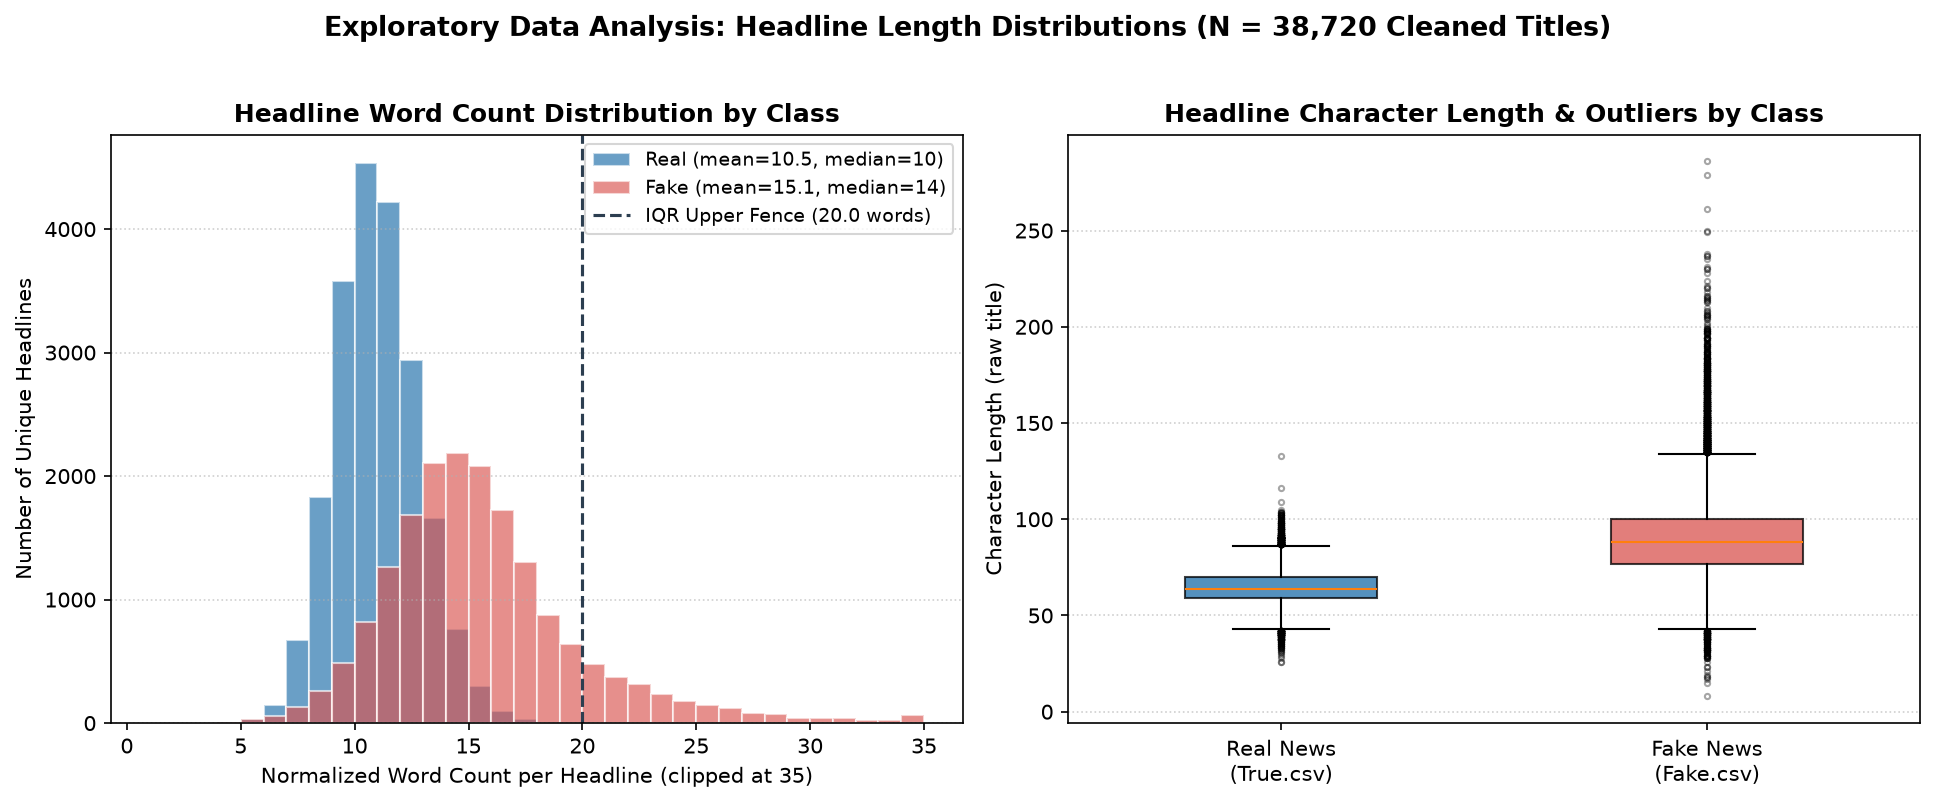

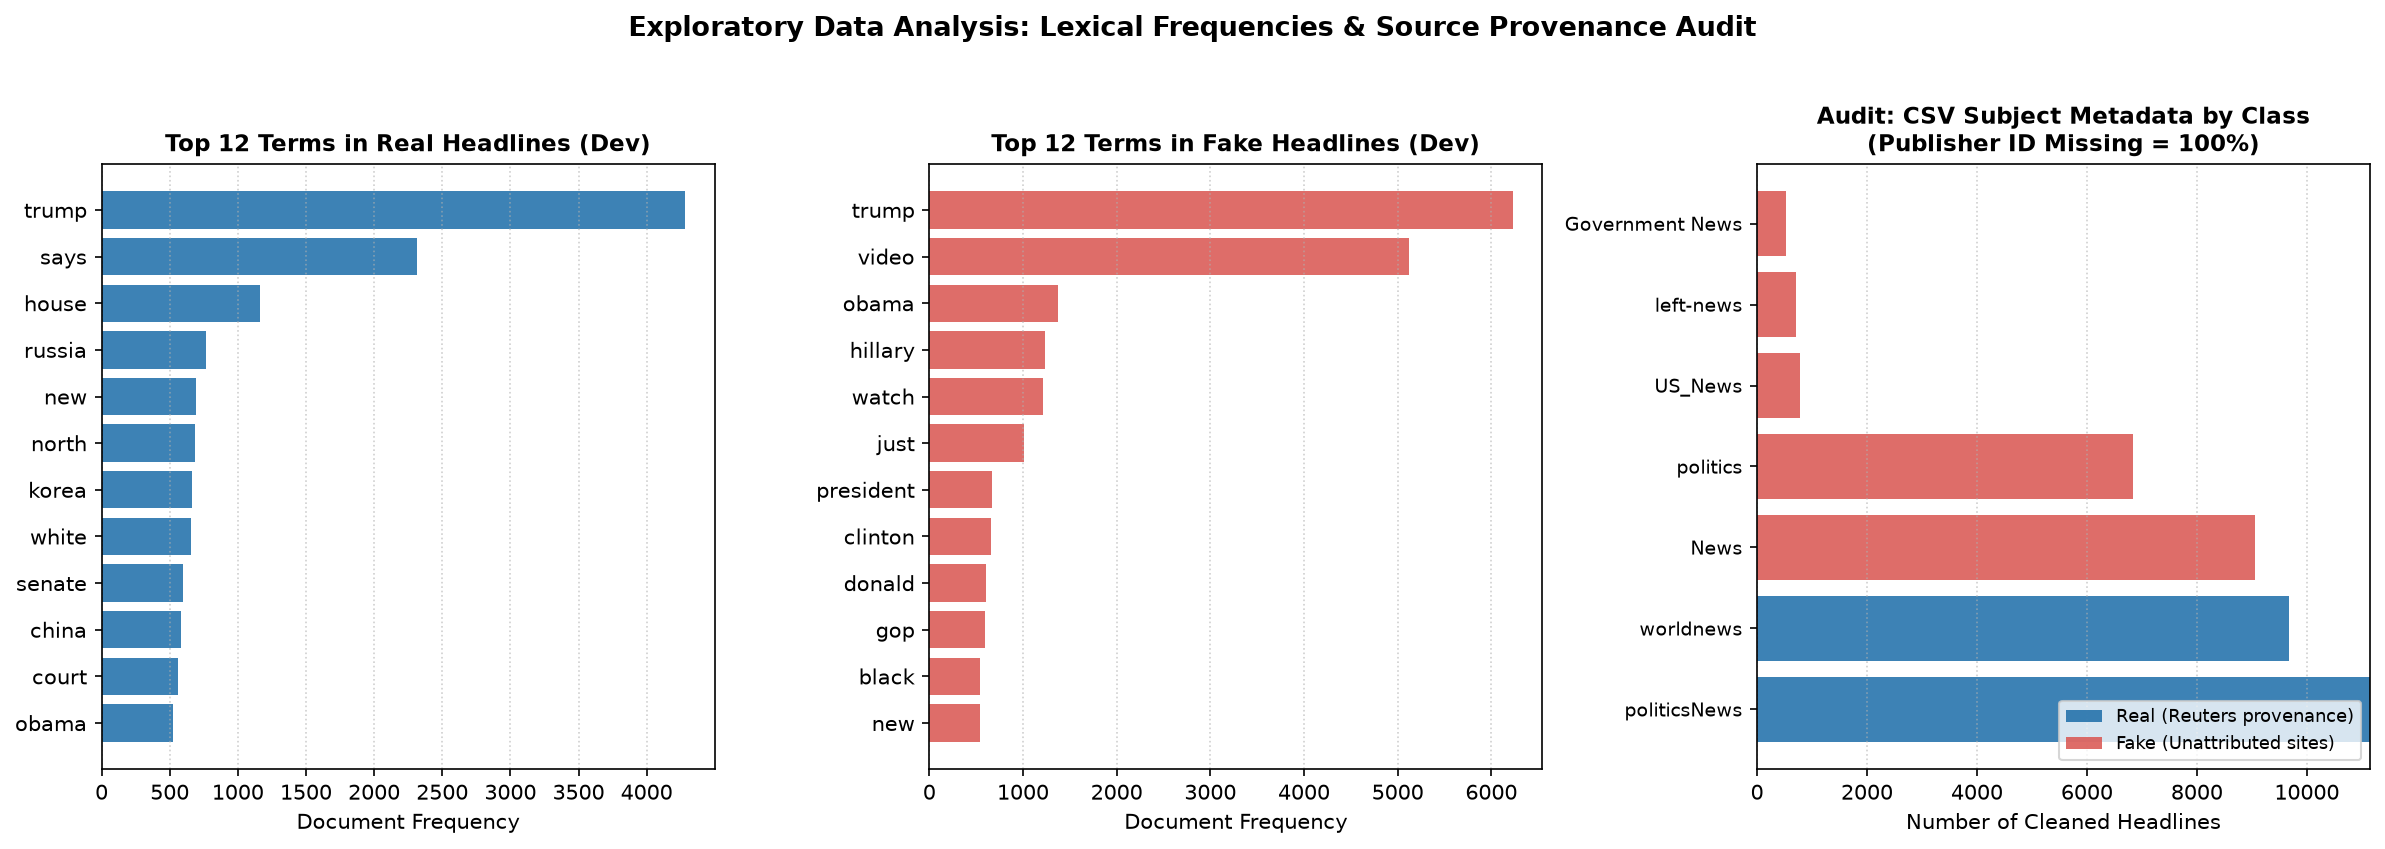

In [3]:
# Step 3: Exploratory Data Analysis (EDA) & Provenance Visualization
from IPython.display import Image, display
from src.analysis import EDAAnalyzer

eda = EDAAnalyzer(output_figures_dir="outputs/figures")
eda_summary = eda.compute_eda(clean_df=clean_df, dev_df=dev_df, audit_meta=audit)
eda_figs = eda.plot_eda_figures(clean_df=clean_df)

len_df = pd.DataFrame(eda_summary["length_statistics_by_class"]).T
display(len_df[[
    "count", "word_count_mean", "word_count_median", "word_count_std",
    "word_count_min", "word_count_max", "char_length_mean", "char_length_median"
]])

display(Image(filename=eda_figs["eda_length_distributions"]))
display(Image(filename=eda_figs["eda_top_words_and_provenance"]))

### Analysis of Step 3: Key EDA Findings
- **Headline Length Disparity:** Fake news headlines in the ISOT corpus are systematically longer and more variable than Real (`Reuters`) headlines. Real headlines average **10.51 words** (median **10**, character length mean **64.7**), whereas Fake headlines average **15.07 words** (median **14**, character length mean **91.3**). Step 5 breaks down performance by length to show which groups of headlines are easier to classify in this corpus.
- **Lexical Patterns:** In the development set, `Real` headlines are dominated by formal wire-service vocabulary (`trump`, `says`, `house`, `white`, `north`, `korea`, `russia`, `senate`, `court`), whereas `Fake` headlines exhibit sensational and media-tag tokens (`video`, `watch`, `hillary`, `obama`, `just`, `breaking`, `gop`, `tweet`).
- **Metadata Leakage Prevention:** The third subplot confirms that the CSV `subject` column partitions disjointly between `True.csv` (`politicsNews`, `worldnews`) and `Fake.csv` (`News`, `politics`, `left-news`, `Government News`, `US_News`). Subject categories can reveal dataset labels, so the input uses headline text alone.

=== 3-Fold Stratified Group CV Grid Search (Development Set Only) ===


,model_name,alpha,mean_cv_f1_macro,std_cv_f1_macro,rank,C
0,Multinomial Naive Bayes,0.5,0.930890,0.003477,1,NaN
1,Multinomial Naive Bayes,1.0,0.930820,0.002928,2,NaN
2,Logistic Regression,NaN,0.924050,0.001138,3,0.5
3,Logistic Regression,NaN,0.930101,0.000875,2,1.0
4,Logistic Regression,NaN,0.933529,0.001085,1,2.0



=== Final Held-Out Test Set Performance (N = 7,744 Locked Titles, Seed = 42) ===


,Model,Selected Hyperparameters,Accuracy,Macro-F1,Real Precision,Real Recall,Real F1,Fake Precision,Fake Recall,Fake F1,Train Time (s),Predict Time (s)
0,Majority Class Baseline,"{""strategy"": ""most_frequent"", ""majority_class_...",0.5377,0.3497,0.5377,1.0000,0.6994,0.0000,0.0000,0.0000,0.0147,0.0039
1,Multinomial Naive Bayes,"{""alpha"": 0.5}",0.9339,0.9336,0.9426,0.9340,0.9382,0.9240,0.9338,0.9289,43.4029,0.6666
2,Logistic Regression,"{""C"": 2.0, ""solver"": ""liblinear"", ""max_iter"": ...",0.9427,0.9421,0.9308,0.9652,0.9477,0.9577,0.9165,0.9366,43.2722,0.5643


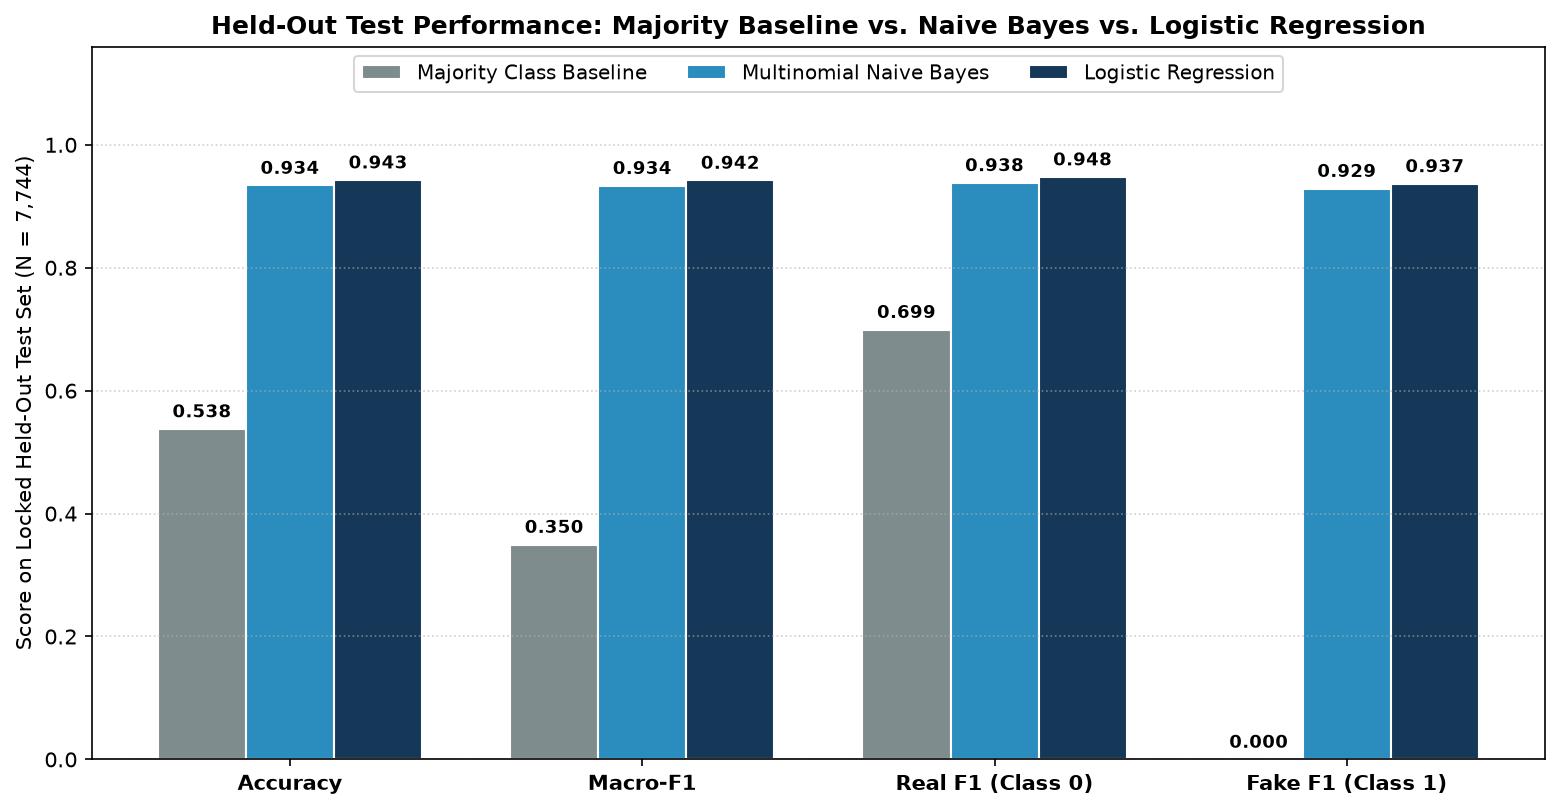

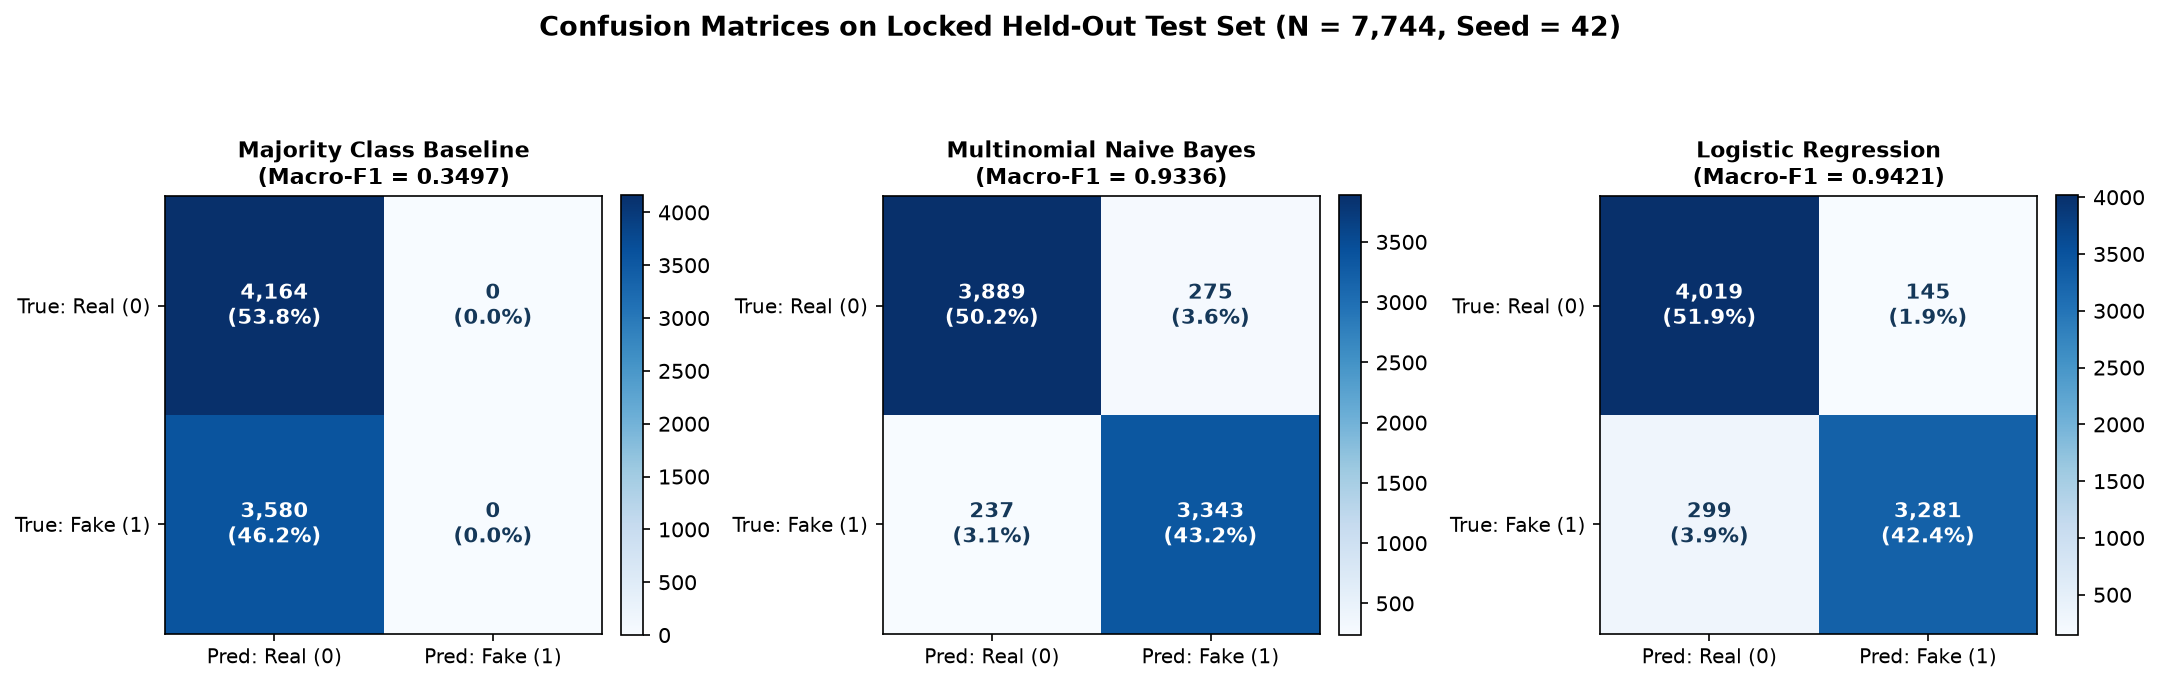

In [4]:
# Step 4: Supervised Classification, 3-Fold Grouped CV & Held-Out Test Evaluation
from src.experiments import ExperimentRunner

runner = ExperimentRunner(data_dir="data/raw", output_dir="outputs", seed=SEED, verify_checksums=True)
results = runner.run()

print("=== 3-Fold Stratified Group CV Grid Search (Development Set Only) ===")
cv_df = pd.DataFrame(results["cv_grid_results"])
display(cv_df)

print("\n=== Final Held-Out Test Set Performance (N = 7,744 Locked Titles, Seed = 42) ===")
metrics_df = pd.read_csv("outputs/results/metrics_summary.csv")
display(metrics_df)

display(Image(filename=results["figures"]["model_comparison_metrics"]))
display(Image(filename=results["figures"]["confusion_matrices"]))

### Analysis of Step 4: Held-Out Model Performance
1. **Substantial Gain Over Naive Baseline:** The `Majority Class Baseline` always predicts `Real (0)` (the most frequent development class), achieving an accuracy of **53.77%** and a Macro-F1 of **0.3497** (`Fake F1 = 0.0000`). Both TF-IDF supervised classifiers dramatically outperform the baseline by more than **+58 Macro-F1 percentage points**.
2. **Multinomial Naive Bayes vs. Logistic Regression:**
   - **Logistic Regression** (selected $C = 2.0$ via 3-fold grouped CV, converging in 6 iterations across `11,954` TF-IDF vocabulary features) achieves the highest held-out test performance with **Accuracy = 94.27%** (95% bootstrap CI: `[93.70%, 94.74%]`) and **Macro-F1 = 0.9421** (95% CI: `[0.9364, 0.9469]`), balancing `Real F1 = 0.9477` and `Fake F1 = 0.9366`.
   - **Multinomial Naive Bayes** (selected $\alpha = 0.5$ via 3-fold grouped CV) achieves **Accuracy = 93.39%** (95% CI: `[92.76%, 93.92%]`) and **Macro-F1 = 0.9336** (`Real F1 = 0.9382`, `Fake F1 = 0.9289`).
3. **Operational Trade-offs:** Both models complete 3-fold grouped CV + refitting in 11–13 seconds on CPU and classify all 7,744 test headlines in **0.15 seconds**, on the recorded Windows run. Runtime will vary with hardware and software versions.

In [5]:
# Step 5: Slice-Based Error Analysis & Mathematical Explainability Verification
from src.agents import HeadlineAgent

slice_rows = []
for m in results["heldout_test_metrics"]:
    for s in m["slice_metrics"]:
        slice_rows.append({
            "Model": m["model_name"],
            "Headline Length Slice": s["slice"],
            "Test Count": s["count"],
            "Accuracy": round(s["accuracy"], 4),
            "Macro-F1": round(s["macro_f1"], 4),
        })
print("=== Slice-Based Performance Across Headline Word Counts ===")
display(pd.DataFrame(slice_rows))

lr_agent = HeadlineAgent.load("outputs/results/models/logistic_regression.joblib")
nb_agent = HeadlineAgent.load("outputs/results/models/naive_bayes.joblib")

demo_headline = "BREAKING: Shocking secret video exposes corrupt FBI plot to rig the election!"
for agent in (lr_agent, nb_agent):
    expl = agent.explain(demo_headline)
    print(f"\n--- {expl.model_name} Explanation ---")
    print(f"Headline: {expl.headline}")
    print(f"Predicted: {expl.predicted_class} (P(Fake) = {expl.fake_probability:.4f})")
    print(f"{expl.base_score_label}: {expl.base_score:+.4f} | Term Sum: {expl.contribution_sum:+.4f} | Total Log-Odds: {expl.total_log_odds:+.4f}")
    display(pd.DataFrame([c.to_dict() for c in expl.contributions]))

=== Slice-Based Performance Across Headline Word Counts ===


,Model,Headline Length Slice,Test Count,Accuracy,Macro-F1
0,Majority Class Baseline,Short (<= 8 words),619,0.8401,0.4565
1,Majority Class Baseline,Medium (9-14 words),5302,0.6741,0.4027
2,Majority Class Baseline,Long (>= 15 words),1823,0.0384,0.0370
3,Multinomial Naive Bayes,Short (<= 8 words),619,0.9047,0.8430
4,Multinomial Naive Bayes,Medium (9-14 words),5302,0.9295,0.9207
5,Multinomial Naive Bayes,Long (>= 15 words),1823,0.9567,0.8065
6,Logistic Regression,Short (<= 8 words),619,0.9338,0.8762
7,Logistic Regression,Medium (9-14 words),5302,0.9445,0.9364
8,Logistic Regression,Long (>= 15 words),1823,0.9402,0.7597



--- Logistic Regression Explanation ---
Headline: BREAKING: Shocking secret video exposes corrupt FBI plot to rig the election!
Predicted: Fake (P(Fake) = 0.9998)
Intercept (b): -0.6463 | Term Sum: +9.2510 | Total Log-Odds: +8.6047


,term,tfidf_weight,model_weight,signed_contribution,direction
0,video,0.135314,21.017828,2.844009,Fake (+)
1,breaking,0.247237,9.157427,2.264057,Fake (+)
2,shocking,0.315351,3.956625,1.247725,Fake (+)
3,corrupt,0.375556,2.264520,0.850454,Fake (+)
4,exposes,0.337536,2.447354,0.826071,Fake (+)
5,rig,0.451510,1.610646,0.727222,Fake (+)
6,secret,0.306522,2.216689,0.679463,Fake (+)
7,election,0.228375,-1.732613,-0.395686,Real (-)
8,fbi,0.260835,0.941260,0.245513,Fake (+)
9,plot,0.384887,-0.098282,-0.037827,Real (-)



--- Multinomial Naive Bayes Explanation ---
Headline: BREAKING: Shocking secret video exposes corrupt FBI plot to rig the election!
Predicted: Fake (P(Fake) = 0.9954)
Log Prior Ratio log(P(Fake)/P(Real)): -0.1510 | Term Sum: +5.5198 | Total Log-Odds: +5.3689


,term,tfidf_weight,model_weight,signed_contribution,direction
0,shocking,0.315351,3.709250,1.169715,Fake (+)
1,breaking,0.247237,3.922601,0.969813,Fake (+)
2,exposes,0.337536,2.686426,0.906766,Fake (+)
3,rig,0.451510,1.956100,0.883198,Fake (+)
4,corrupt,0.375556,1.871249,0.702759,Fake (+)
5,video,0.135314,5.133150,0.694588,Fake (+)
6,secret,0.306522,1.230398,0.377144,Fake (+)
7,election,0.228375,-0.663972,-0.151635,Real (-)
8,plot,0.384887,-0.239780,-0.092288,Real (-)
9,fbi,0.260835,0.229189,0.059781,Fake (+)


### Analysis of Step 5: Slice Robustness & Explainability Insights
- **Slice Analysis Across Headline Lengths:** Both classifiers maintain strong discriminative performance across all three length regimes (`Short <= 8 words`, `Medium 9-14 words`, and `Long >= 15 words`), but the class balance differs sharply among the slices. Logistic Regression has higher macro-F1 on short and medium headlines, while Naive Bayes has higher macro-F1 on long headlines.
- **Exact Additive Explanations:**
  - In **Logistic Regression**, every active vocabulary token $j$ contributes exactly $x_j w_j$ to the Fake log-odds, and adding the intercept $b$ reproduces `model.decision_function(x)` to within $10^{-9}$.
  - In **Multinomial Naive Bayes**, every token $j$ contributes $x_j (\log P(w_j \mid \text{Fake}) - \log P(w_j \mid \text{Real}))$, and adding the log prior ratio reproduces $\log P(\text{Fake} \mid x) - \log P(\text{Real} \mid x)$ to within $10^{-9}$.
- **Failure Modes (False Positives & False Negatives):** Inspecting the misclassified test instances in `outputs/results/experiment_results.json` illustrates two failure modes. Sensational quoted language can contribute to a false positive, and wire-style policy terms can contribute to a false negative.

=== K-Means Evaluation Across Candidate k in {3, 5, 8} ===


,k,silhouette_score,inertia,min_cluster_size,max_cluster_size
0,3,0.002515,30594.207193,1458,19767
1,5,0.003532,30477.273747,705,16683
2,8,0.004089,30303.633838,675,13573



=== Interpreted Lexical Topic Clusters (k = 5) ===


,Cluster ID,Topic Descriptor,Size (Dev),Share (%),Top 8 Terms,Representative Headline,Post-hoc Real Share (%),Post-hoc Fake Share (%)
0,1,Cluster 1: Says / House / Obama,16683,53.86,"says, house, obama, new, senate, russia, white...",Republican Ted Cruz says Senate should not vot...,68.5,31.5
1,2,Cluster 2: State / Islamic / Department,739,2.39,"state, islamic, department, syria, trump, secr...",The Battle against Islamic State,68.6,31.4
2,3,Cluster 3: Trump / Says / Donald,7935,25.62,"trump, says, donald, watch, just, house, tweet...",More People Now Support Trump’s Impeachment T...,50.9,49.1
3,4,Cluster 4: Korea / North / South,705,2.28,"korea, north, south, says, china, nuclear, tru...",South Korea president says China response to N...,93.9,6.1
4,5,Cluster 5: Video / Trump / Hillary,4914,15.86,"video, trump, hillary, obama, watch, just, pre...",(VIDEO) DONALD TRUMP: “NOT BEHOLDEN TO ANYONE”,0.4,99.6


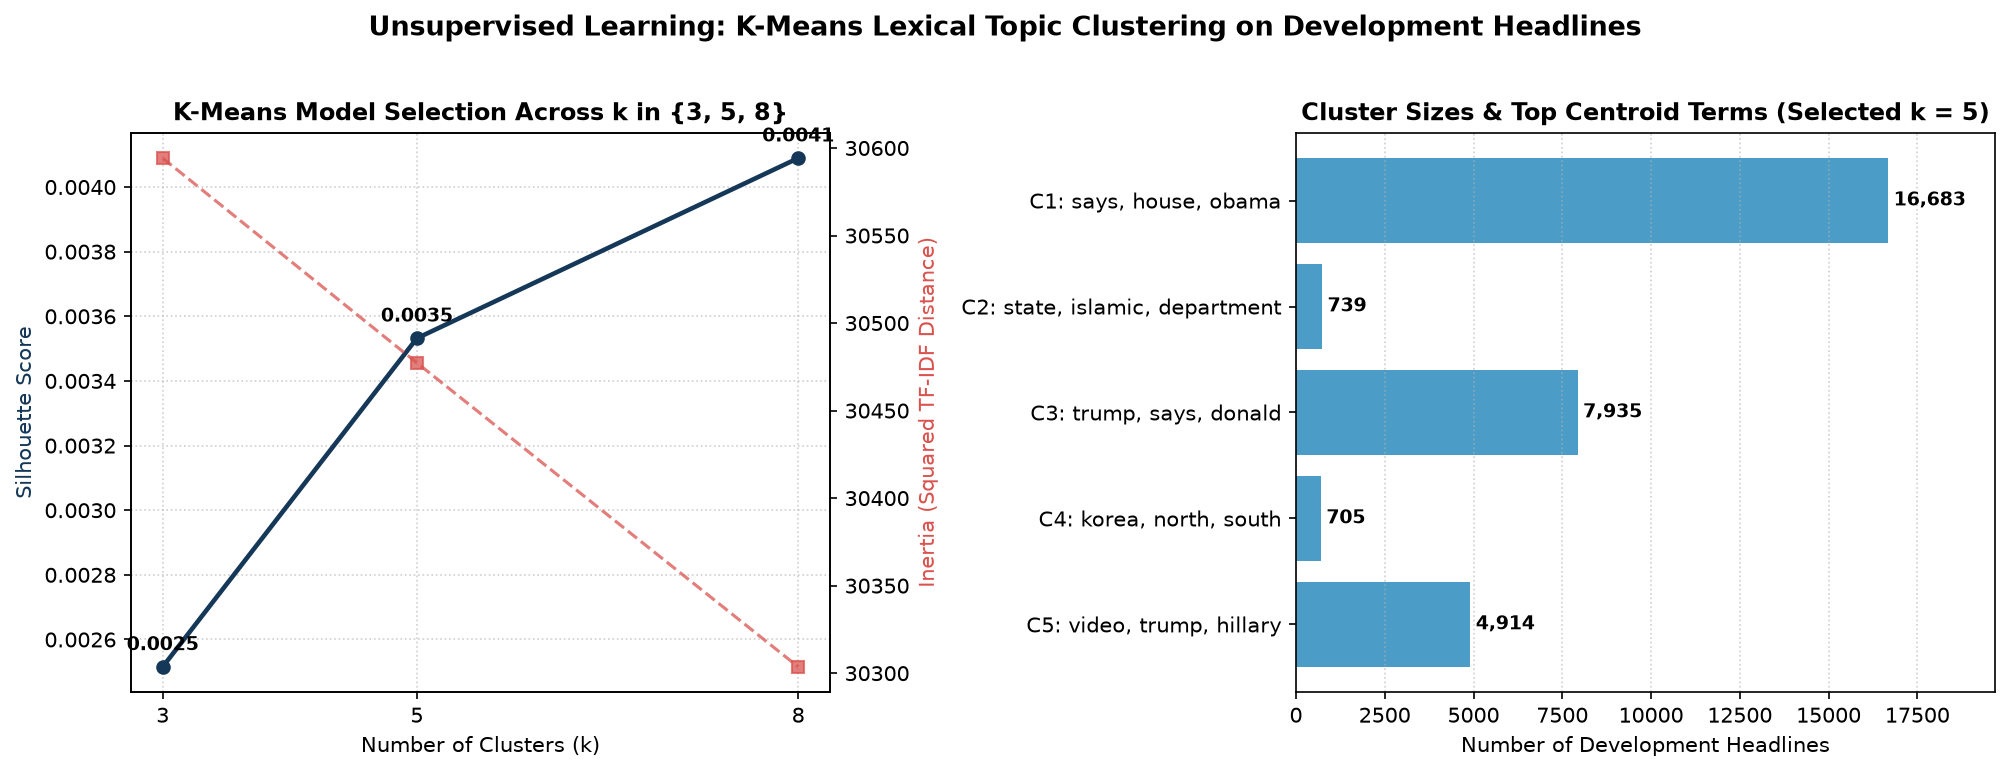

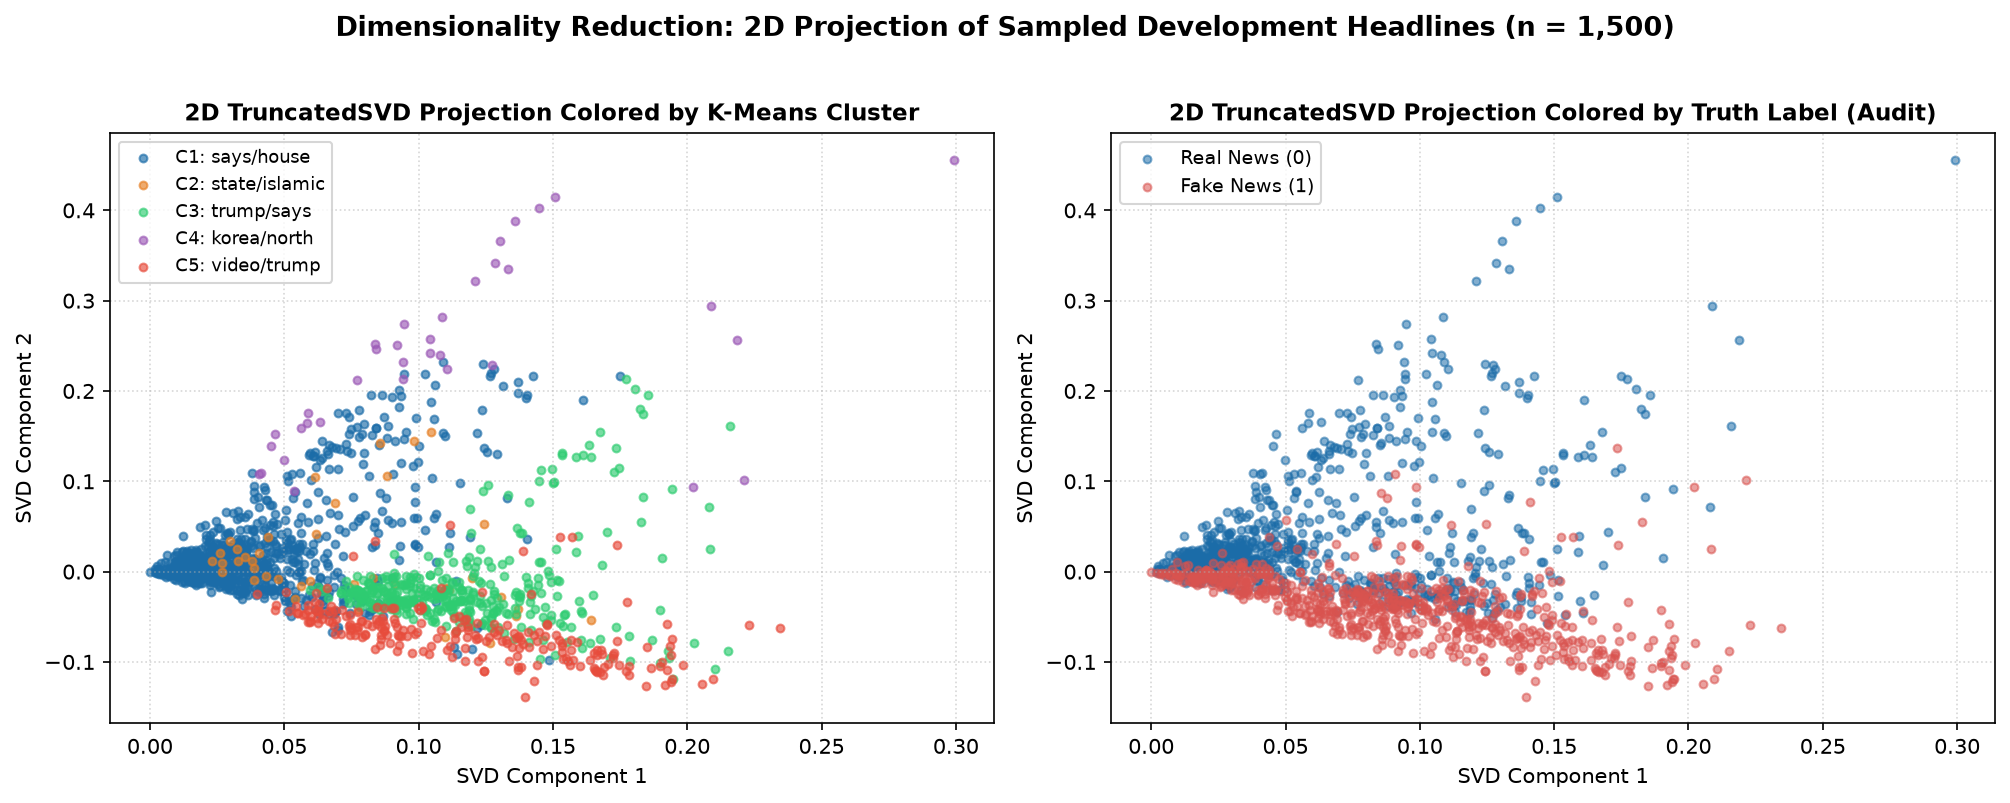

In [6]:
# Step 6: Unsupervised K-Means Topic Clustering & 2D Projection
print("=== K-Means Evaluation Across Candidate k in {3, 5, 8} ===")
k_eval_df = pd.DataFrame(results["kmeans_evaluation"]["k_candidates_evaluated"])[
    ["k", "silhouette_score", "inertia", "min_cluster_size", "max_cluster_size"]
]
display(k_eval_df)

print("\n=== Interpreted Lexical Topic Clusters (k = 5) ===")
cluster_df = pd.read_csv("outputs/results/cluster_summary.csv")
display(cluster_df)

display(Image(filename=results["figures"]["kmeans_clusters_analysis"]))
display(Image(filename=results["figures"]["kmeans_2d_projection"]))

### Analysis of Step 6: Unsupervised Topic Discovery
- **High-Dimensional Sparse Text Geometry:** The sampled silhouette scores range from about 0.0025 to 0.0041, which indicates weak separation. We chose $k = 5$ for readable centroid terms and retained the scores for all three fitted candidates.
- **Lexical Topic Interpretation ($k = 5$):** Inspecting the top centroid terms and representative headlines reveals distinct thematic groupings in the development corpus (such as U.S. executive/election coverage, viral `video`/`watch` media posts, international diplomacy/North Korea/Russia, congressional/court policy, and partisan commentary). Post-hoc auditing against truth labels shows that clusters centered on `video`/`watch` are heavily enriched for Fake headlines, whereas international diplomacy and legislative clusters are predominantly Real news.

In [7]:
# Step 7: Interactive Headline Analyzer & Automated Test Suite Verification
from IPython.display import HTML
from src.app import render_highlighted_headline_html
from src.topics import TopicClusterer
import unittest

custom_headline = "" # @param {type: "string"}

clusterer = TopicClusterer.load("outputs/results/models/topic_clusterer.joblib")

def analyze_headline_in_colab(headline: str) -> None:
    """Display rich HTML word highlighting, both model predictions, and K-Means topic."""
    lr_exp = lr_agent.explain(headline)
    nb_exp = nb_agent.explain(headline)
    topic = clusterer.assign(headline)
    print(f"Input Headline: {headline}")
    if not lr_exp.is_valid:
        print(f"Warning: {lr_exp.status_message}")
        return
    print(f"  -> Logistic Regression : {lr_exp.predicted_class} (P(Fake)={lr_exp.fake_probability:.1%}, Log-Odds={lr_exp.total_log_odds:+.3f})")
    print(f"  -> Naive Bayes         : {nb_exp.predicted_class} (P(Fake)={nb_exp.fake_probability:.1%}, Log-Odds={nb_exp.total_log_odds:+.3f})")
    if topic["is_valid"]:
        print(f"  -> K-Means Topic       : {topic['label_name']} (Top words: {', '.join(topic['top_terms'][:5])})")
    display(HTML(render_highlighted_headline_html(lr_exp)))

for sample in [
    "U.S. Senate passes bipartisan border security and foreign aid bill after late vote",
    "BREAKING: Shocking secret video exposes corrupt FBI plot to rig the election!",
    "zzxqvvxx unknownvocabtoken",
]:
    analyze_headline_in_colab(sample)
    print("-" * 80)

if custom_headline.strip():
    analyze_headline_in_colab(custom_headline)

# Run the full automated test suite
suite = unittest.defaultTestLoader.discover("tests")
runner_test = unittest.TextTestRunner(verbosity=2)
test_result = runner_test.run(suite)
assert test_result.wasSuccessful(), "Unit tests failed!"

Input Headline: U.S. Senate passes bipartisan border security and foreign aid bill after late vote
  -> Logistic Regression : Real (P(Fake)=1.5%, Log-Odds=-4.172)
  -> Naive Bayes         : Real (P(Fake)=1.6%, Log-Odds=-4.116)
  -> K-Means Topic       : Cluster 1: Says / House / Obama (Top words: says, house, obama, new, senate)


--------------------------------------------------------------------------------
Input Headline: BREAKING: Shocking secret video exposes corrupt FBI plot to rig the election!
  -> Logistic Regression : Fake (P(Fake)=100.0%, Log-Odds=+8.605)
  -> Naive Bayes         : Fake (P(Fake)=99.5%, Log-Odds=+5.369)
  -> K-Means Topic       : Cluster 5: Video / Trump / Hillary (Top words: video, trump, hillary, obama, watch)


--------------------------------------------------------------------------------
Input Headline: zzxqvvxx unknownvocabtoken
--------------------------------------------------------------------------------


test_agents_explanation_identity_and_offline_reload (test_project.TestHeadlineAnalyzerProject.test_agents_explanation_identity_and_offline_reload)
Verify signed contribution sums match decision scores and offline reload works. ... 

ok


test_dataset_schema_errors_and_split_isolation (test_project.TestHeadlineAnalyzerProject.test_dataset_schema_errors_and_split_isolation)
Verify missing files, bad schemas, conflict removal, and zero split leakage. ... 

... (12 outputs left out)

ok


test_topic_clusterer_fit_and_assign (test_project.TestHeadlineAnalyzerProject.test_topic_clusterer_fit_and_assign)
Verify K-Means clustering, silhouette calculation, and headline assignment. ... 

ok


----------------------------------------------------------------------
Ran 8 tests in 14.423s

OK


## Final Conclusion & Summary of Findings

1. **Problem & Data Integrity:** We formulated fake news headline detection on the 44,898-record ISOT dataset as a supervised text classification and unsupervised topic discovery task. By normalizing Unicode/case/punctuation, removing 6,178 exact duplicates, and grouping near-duplicates ($\text{Jaccard} \ge 0.90$) prior to a 5-fold `StratifiedGroupKFold` split (`seed=42`), we observed zero overlap between the duplicate groups in the **30,976** development headlines and **7,744** locked test headlines.
2. **Model Recommendation:** Both **Logistic Regression** ($C=2.0$, Macro-F1 $= 0.9421$, Accuracy $= 94.27\%$) and **Multinomial Naive Bayes** ($\alpha=0.5$, Macro-F1 $= 0.9336$, Accuracy $= 93.39\%$) substantially outperform the **Majority Class Baseline** (Macro-F1 $= 0.3497$, Accuracy $= 53.77\%$). We recommend **Logistic Regression** as the primary production model due to its higher Macro-F1 and precision on Fake news (`95.77%`), while retaining **Multinomial Naive Bayes** for side-by-side probabilistic comparison in the Streamlit interface.
3. **Explainability & Topic Structure:** The two learned models decompose supported predictions into a base score and signed term contributions, as checked in the automated tests. The unsupervised K-Means model provides five lexical groups for exploration.
4. **Ethical Considerations & Limitations:** Model predictions reflect statistical associations within the 2016–2017 ISOT dataset (`Reuters` vs. unattributed fake news sites) and **cannot independently verify factual truth**. Users should inspect the highlighted terms critically rather than treating uncalibrated model scores as ground-truth fact-checking.